In [1]:
# Use vis kernel
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt; plt.rc('font', size=18)
from collections import Counter
# import holoviews as hv; hv.extension('bokeh')
# import plotly.graph_objects as go
# from bokeh.io import export_svgs
# import upsetplot as up

In [2]:
taxa = ['B_cellulosilyticus_WH2', 
        'B_caccae', 
        'B_vulgatus', 
        'B_thetaiotaomicron', 
        'B_ovatus', 
        'R_obeum', 
        'B_uniformis', 
        'P_distasonis', 
        'C_scindens', 
        'C_aerofaciens', 
        'C_spiroforme', 
        # 'D_longicatena'
        ]

cols = ['#016bff',
        '#b91f1c',
        '#308937',
        '#ff8137',
        '#6f4fc7',
        '#d4b300',
        '#893a2b',
        '#ff6c79',
        '#16c4ff',
        '#766f41',
        '#00c800',
        # '#af3261'
        ]

grey = ['#99aab5']*26

cols_comp = cols + grey

# pretty_names_dir = {'B_caccae': '$B. caccae$',
#                 'B_cellulosilyticus_WH2': '$B. cellulosilyticus$',
#                 'B_ovatus': '$B. ovatus$',
#                 'B_thetaiotaomicron': '$B. thetaiotaomicron$',
#                 'B_uniformis': '$B. uniformis$',
#                 'B_vulgatus': '$B. vulgatus$',
#                 'C_aerofaciens': '$C. aerofaciens$',
#                 'C_scindens': '$C. scindens$',
#                 'C_spiroforme': '$C. spiroforme$',
#                 # 'D_longicatena': '$D. longicatena$',
#                 'P_distasonis': '$P. distasonis$',
#                 'R_obeum': '$R. obeum$'
#                 }

pretty_names_dir_ = {'B_caccae': 'B. caccae',
                'B_cellulosilyticus_WH2': 'B. cellulosilyticus',
                'B_ovatus': 'B. ovatus',
                'B_thetaiotaomicron': 'B. thetaiotaomicron',
                'B_uniformis': 'B. uniformis',
                'B_vulgatus': 'B. vulgatus',
                'C_aerofaciens': 'C. aerofaciens',
                'C_scindens': 'C. scindens',
                'C_spiroforme': 'C. spiroforme',
                # 'D_longicatena': 'D. longicatena',
                'P_distasonis': 'P. distasonis',
                'R_obeum': 'R. obeum'
                }

pretty_names_dir = {'B_caccae': 'Bca',
                'B_cellulosilyticus_WH2': 'Bce',
                'B_ovatus': 'Bov',
                'B_thetaiotaomicron': 'Bth',
                'B_uniformis': 'Bun',
                'B_vulgatus': 'Bvu',
                'C_aerofaciens': 'Cae',
                'C_scindens': 'Csc',
                'C_spiroforme': 'Csp',
                # 'D_longicatena': 'Dlo',
                'P_distasonis': 'Pdi',
                'R_obeum': 'Rob'
                }

cols_species_map = dict(zip(taxa, cols))
cols_ = list(zip(taxa, cols))
cols_

[('B_cellulosilyticus_WH2', '#016bff'),
 ('B_caccae', '#b91f1c'),
 ('B_vulgatus', '#308937'),
 ('B_thetaiotaomicron', '#ff8137'),
 ('B_ovatus', '#6f4fc7'),
 ('R_obeum', '#d4b300'),
 ('B_uniformis', '#893a2b'),
 ('P_distasonis', '#ff6c79'),
 ('C_scindens', '#16c4ff'),
 ('C_aerofaciens', '#766f41'),
 ('C_spiroforme', '#00c800')]

In [3]:
def drop_nan(x):
    if pd.isna(x):
        return False
    else:
        return True
    
def presence_absence(x):
    if pd.isna(x):
        return 0
    else:
        return 1

# def export_svg(obj, filename):
#     plot_state = hv.renderer('bokeh').get_plot(obj).state
#     plot_state.output_backend = 'svg'
#     export_svgs(plot_state, filename=filename)

# PULs content

In [11]:
puls = []
for taxon in taxa:
    cgcs = pd.read_table(f'dbCAN3/{taxon}/sub.prediction.out')
    cgcs['Species'] = taxon
    cgcs['Species'] = cgcs['Species'].map(pretty_names_dir)
    cgcs.set_index('Species', inplace=True)
    puls.append(cgcs)
puls = pd.concat(puls, axis=0)
with pd.ExcelWriter('PULs/puls.xlsx') as writer:
    puls.to_excel(writer, sheet_name= 'puls', index=True, header=True)
puls

,#cgcid,PULID,dbCAN-PUL substrate,bitscore,signature pairs,dbCAN-Sub substrate,dbCAN-Sub substrate score
Species,,,,,,,
Bce,ATFI01000008.1|CGC16,PUL0503,capsule polysaccharide synthesis,2226.4,CAZyme-CAZyme;CAZyme-CAZyme;TC-TC,NaN,NaN
Bce,ATFI01000005.1|CGC1,PUL0479,pectin,2776.0,CAZyme-CAZyme;CAZyme-CAZyme;CAZyme-CAZyme;CAZy...,NaN,NaN
Bce,ATFI01000001.1|CGC11,PUL0145,glycosaminoglycan,6080.0,CAZyme-CAZyme;TC-TC;TC-TC;TC-TC,NaN,NaN
Bce,ATFI01000009.1|CGC3,PUL0540,starch,1410.0,TC-TC;CAZyme-CAZyme,NaN,NaN
Bce,ATFI01000004.1|CGC5,PUL0258,capsule polysaccharide synthesis,904.7,CAZyme-CAZyme;CAZyme-CAZyme;CAZyme-CAZyme;CAZy...,NaN,NaN
...,...,...,...,...,...,...,...
Csp,ABIK02000015.1|CGC5,PUL0452,capsule polysaccharide synthesis,1221.5,CAZyme-CAZyme;CAZyme-CAZyme;CAZyme-CAZyme;CAZy...,NaN,NaN
Csp,ABIK02000007.1|CGC1,PUL0502,capsule polysaccharide synthesis,719.7,CAZyme-CAZyme;TC-TC,NaN,NaN
Csp,ABIK02000015.1|CGC1,NaN,NaN,NaN,NaN,hostglycan,4.0


## UpSet Plot

In [4]:
puls = []
for taxon in taxa:
    cgcs = pd.read_table(f'dbCAN3/{taxon}/sub.prediction.out')
    cgcs['Species'] = taxon
    cgcs = cgcs[cgcs['PULID'].apply(drop_nan)].copy()
    cgcs.drop_duplicates(subset=['PULID'], inplace=True)
    cgcs.set_index('PULID', inplace=True)
    cgcs = cgcs.loc[:,['Species']].copy()
    cgcs.columns = [cgcs['Species'][0]]
    puls.append(cgcs)
puls = pd.concat(puls, axis=1)
puls.columns = puls.columns.map(pretty_names_dir)
puls = puls.applymap(presence_absence)
puls = puls.astype(bool)
puls

,Bce,Bca,Bvu,Bth,Bov,Rob,Bun,Pdi,Csc,Cae,Csp
PULID,,,,,,,,,,,
PUL0503,True,False,False,False,False,False,False,False,False,False,False
PUL0479,True,False,False,False,False,False,False,False,False,False,False
PUL0145,True,True,False,True,True,False,True,False,False,False,False
PUL0540,True,False,False,False,False,False,False,False,False,False,False
PUL0258,True,False,False,True,False,False,True,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
PUL0196,False,False,False,False,False,False,False,False,False,True,False
PUL0158,False,False,False,False,False,False,False,False,False,True,False
PUL0452,False,False,False,False,False,False,False,False,False,False,True


In [5]:
indicators = up.from_indicators(puls)
indicators

Bce    Bca    Bvu    Bth    Bov    Rob    Bun    Pdi    Csc    Cae    Csp  
True   False  False  False  False  False  False  False  False  False  False    1.0
                                                                      False    1.0
       True   False  True   True   False  True   False  False  False  False    1.0
       False  False  False  False  False  False  False  False  False  False    1.0
                     True   False  False  True   True   False  False  False    1.0
                                                                              ... 
False  False  False  False  False  False  False  False  False  True   False    1.0
                                                                      False    1.0
                                                               False  True     1.0
                                                                      True     1.0
                                                                      True     1.0
Name: ones,

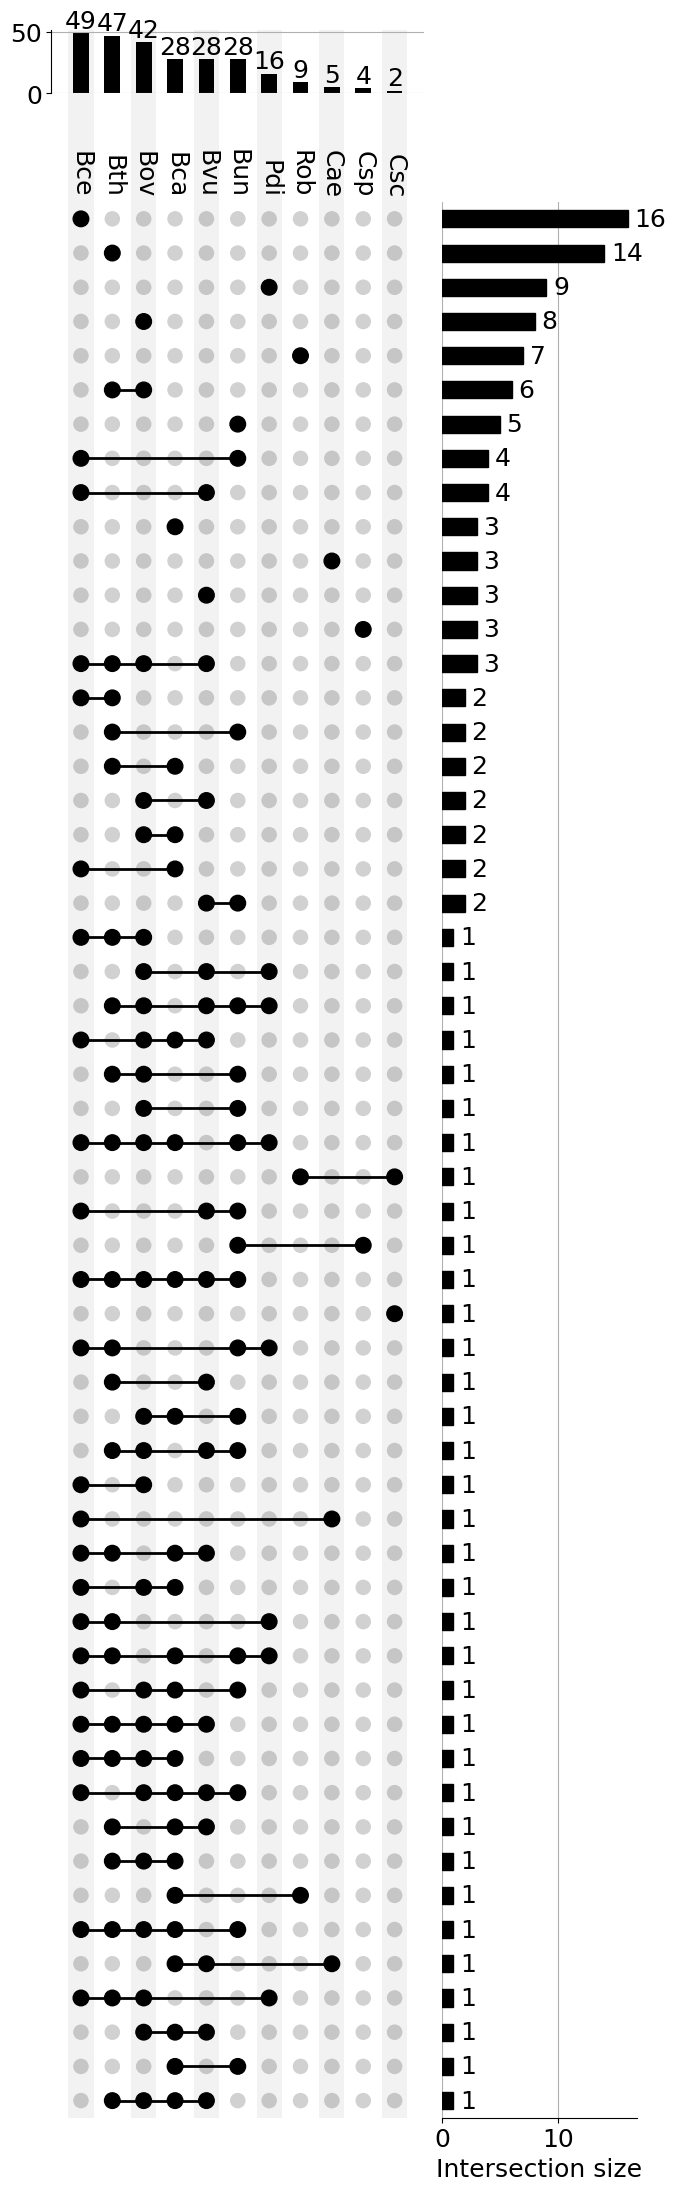

In [6]:
up.plot(indicators, subset_size='count', show_counts=True, orientation='vertical', sort_by='cardinality')
# plt.title('PULs shared by members of the community', fontsize=16)
plt.savefig('PULs/PULs_shared.svg', bbox_inches='tight')
plt.show()

# Substrate prediction

## UpSet Plot 

In [7]:
sub_prediction = []
for taxon in taxa:
    subs = pd.read_table(f'dbCAN3/{taxon}/sub.prediction.out')
    subs['Species'] = taxon
    subs = subs[subs['dbCAN-PUL substrate'].apply(drop_nan)].copy()
    subs.drop_duplicates(subset=['dbCAN-PUL substrate'], inplace=True)
    subs.set_index('dbCAN-PUL substrate', inplace=True)
    subs = subs.loc[:,['Species']].copy()
    subs.columns = [subs['Species'][0]]
    sub_prediction.append(subs)
sub_prediction = pd.concat(sub_prediction, axis=1)
sub_prediction.columns = sub_prediction.columns.map(pretty_names_dir)
sub_prediction = sub_prediction.applymap(presence_absence)
sub_prediction = sub_prediction.astype(bool)
sub_prediction

,Bce,Bca,Bvu,Bth,Bov,Rob,Bun,Pdi,Csc,Cae,Csp
dbCAN-PUL substrate,,,,,,,,,,,
capsule polysaccharide synthesis,True,True,True,True,True,True,True,True,True,True,True
pectin,True,True,True,True,True,False,True,True,False,True,False
glycosaminoglycan,True,True,False,True,True,False,True,False,False,False,True
starch,True,False,True,False,True,False,True,True,False,True,False
xylan,True,False,True,False,False,False,False,True,False,False,False
arabinan,True,True,True,True,True,False,False,True,False,False,False
mucin,True,True,True,True,True,False,True,True,False,False,False
agarose,True,False,True,False,False,False,True,False,False,False,False
ribose,True,False,False,False,False,False,False,False,False,False,False


In [8]:
indicators = up.from_indicators(sub_prediction)
indicators

Bce    Bca    Bvu    Bth    Bov    Rob    Bun    Pdi    Csc    Cae    Csp  
True   True   True   True   True   True   True   True   True   True   True     1.0
                                   False  True   True   False  True   False    1.0
              False  True   True   False  True   False  False  False  True     1.0
       False  True   False  True   False  True   True   False  True   False    1.0
                            False  False  False  True   False  False  False    1.0
       True   True   True   True   False  False  True   False  False  False    1.0
                                          True   True   False  False  False    1.0
       False  True   False  False  False  True   False  False  False  False    1.0
              False  False  False  False  False  False  False  False  False    1.0
       True   True   True   True   False  False  False  False  False  False    1.0
              False  True   True   False  True   False  False  False  False    1.0
       Fals

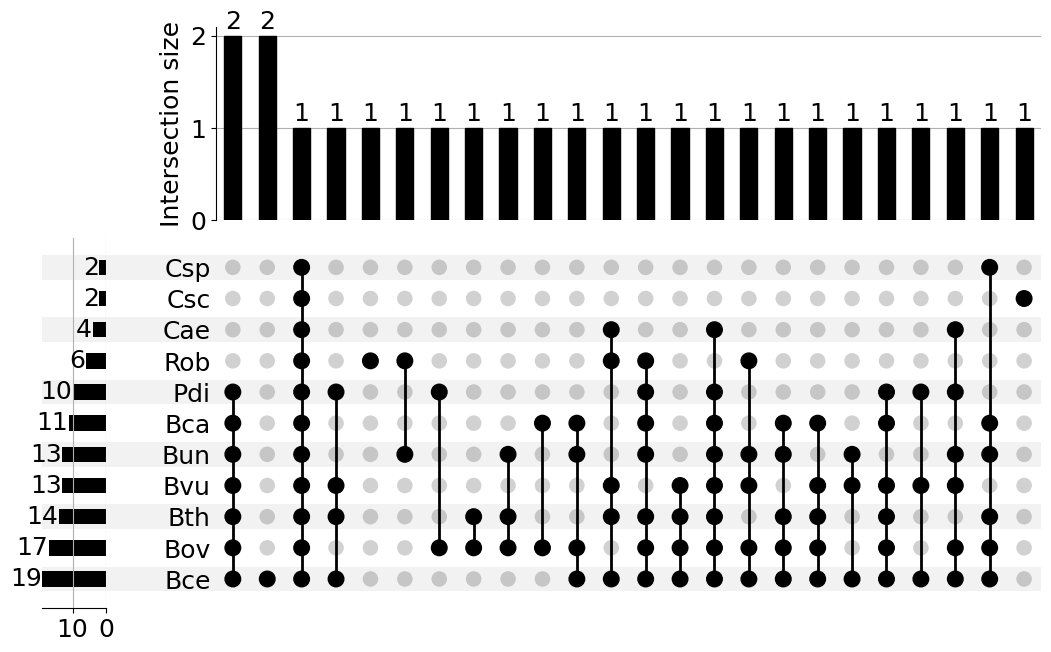

In [9]:
up.plot(indicators, subset_size='count', show_counts=True, orientation='horizontal', sort_by='cardinality')
# plt.title('Number of substrates in common that the species can degrade', fontsize=16)
plt.savefig('PULs/Subs_common.svg', bbox_inches='tight')
plt.show()

## Sankey Plot

In [10]:
sub_prediction = {}
for taxon in taxa:
    subs = pd.read_table(f'dbCAN3/{taxon}/sub.prediction.out')
    subs['Species'] = taxon
    subs.set_index('dbCAN-PUL substrate', inplace=True)
    subs = subs.loc[:,['Species']].copy()
    subs.columns = [subs['Species'][0]]
    subs.reset_index(inplace=True)
    subs = subs[subs['dbCAN-PUL substrate'].apply(drop_nan)].copy()
    subs = Counter(subs['dbCAN-PUL substrate'])
    sub_prediction[taxon] = subs
sub_prediction = pd.DataFrame(sub_prediction)
sub_prediction = sub_prediction.copy()
sub_prediction.index.name = 'Substrate'
sub_prediction.reset_index(inplace=True)
sub_prediction = sub_prediction.melt(id_vars=['Substrate'], var_name='Species', value_name='Count')
sub_prediction['Species'] = sub_prediction['Species'].map(pretty_names_dir_)
sub_prediction = sub_prediction[sub_prediction['Count'].apply(drop_nan)].copy()
sub_prediction = sub_prediction.loc[:,['Species', 'Substrate','Count']].copy()
sub_prediction.columns = ['source', 'target', 'value']
sub_prediction

,source,target,value
0,B. cellulosilyticus,capsule polysaccharide synthesis,8.0
1,B. cellulosilyticus,pectin,16.0
2,B. cellulosilyticus,glycosaminoglycan,6.0
3,B. cellulosilyticus,starch,4.0
4,B. cellulosilyticus,xylan,4.0
...,...,...,...
235,C. aerofaciens,pectin,1.0
237,C. aerofaciens,starch,1.0
251,C. aerofaciens,human milk oligosaccharide,2.0
260,C. spiroforme,capsule polysaccharide synthesis,3.0


In [11]:
sankey = hv.Sankey(sub_prediction, kdims=['source', 'target'], vdims=['value'])
sankey.opts(label_position='outer', 
    edge_color='source', 
    node_color='source', 
    node_width=12,
    node_padding=9,
    iterations=1000,
    cmap=cols_comp,
    edge_alpha=0.6,
    fontsize=20,
    width=1300, 
    height=800
    )

export_svg(sankey, 'PULs/substrate_prediction.svg')
sankey

:Sankey   [source,target]   (value)